# Welcome to Time Series Project

This project aim to predict production forecaste

## Important EDA

### Step 5: Performing Data Transformation

Data transformation prepares the dataset for better analysis and modelling. Depending on the dataset, we may need to modify or convert the data so that it is in a suitable format for analysis.

- Scaling or normalizing numerical variables like min-max scaling or standardization.
- Encoding categorical variables for machine learning like one-hot encoding or label encoding.
- Applying mathematical transformations like logarithmic square root to correct skewness or non linearity.
- Creating new features by deriving useful information from existing variables.
- Aggregating or grouping data based on specific variables or conditions.

## Data

### Prepare the data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
import polars as pl


from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    GroupKFold,
    cross_val_score,
)
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from xgboost import XGBRegressor


import numpy as np
from keras.models import Sequential
from keras.layers import LSTM
from keras.layers import Dense
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns

import statsmodels.api as sm



In [2]:
path=(r"D:\DataSets\Production_data\Volve production data.xlsx")

In [3]:
sheets = pd.read_excel(path, sheet_name=None)
daily_df = sheets["Daily Production Data"]
monthly_df = sheets["Monthly Production Data"]


In [4]:
production_only_wells = (                                    # This cell use literate programming
    daily_df.groupby("NPD_WELL_BORE_NAME")["FLOW_KIND"]
    .agg(set)
    .loc[lambda x: x == {"production"}]
)

production_only_wells

NPD_WELL_BORE_NAME
15/9-F-1 C     {production}
15/9-F-11      {production}
15/9-F-12      {production}
15/9-F-14      {production}
15/9-F-15 D    {production}
Name: FLOW_KIND, dtype: object

In [5]:
production_df = daily_df[daily_df["NPD_WELL_BORE_NAME"].isin(production_only_wells.index.tolist())]
well_12= production_df[production_df["NPD_WELL_BORE_NAME"] == "15/9-F-12"]

In [6]:
split_index = int(len(well_12) * 0.85)

train_df = well_12.iloc[:split_index].copy()
test_df = well_12.iloc[split_index:].copy()

In [7]:
train_df.set_index("DATEPRD", inplace=True)
test_df.set_index("DATEPRD", inplace=True)

### EDA

### Step 1: Understanding the Problem and the Data

The first step in any data analysis project is to fully understand the problem we're solving and the data we have. This includes asking questions like:

- What is the goal or problem we are trying to solve? --> Production forecasting
- What variables are present in the dataset and what do they represent?
- What types of data are available (numerical, categorical, text etc.)?
- Are there any data quality issues or limitations?

In [8]:
train_df.columns

Index(['WELL_BORE_CODE', 'NPD_WELL_BORE_CODE', 'NPD_WELL_BORE_NAME',
       'NPD_FIELD_CODE', 'NPD_FIELD_NAME', 'NPD_FACILITY_CODE',
       'NPD_FACILITY_NAME', 'ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE',
       'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING', 'AVG_ANNULUS_PRESS',
       'AVG_CHOKE_SIZE_P', 'AVG_CHOKE_UOM', 'AVG_WHP_P', 'AVG_WHT_P',
       'DP_CHOKE_SIZE', 'BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL',
       'BORE_WI_VOL', 'FLOW_KIND', 'WELL_TYPE'],
      dtype='object')

In [9]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2597 entries, 2008-02-12 to 2015-06-16
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   WELL_BORE_CODE            2597 non-null   object 
 1   NPD_WELL_BORE_CODE        2597 non-null   int64  
 2   NPD_WELL_BORE_NAME        2597 non-null   object 
 3   NPD_FIELD_CODE            2597 non-null   int64  
 4   NPD_FIELD_NAME            2597 non-null   object 
 5   NPD_FACILITY_CODE         2597 non-null   int64  
 6   NPD_FACILITY_NAME         2597 non-null   object 
 7   ON_STREAM_HRS             2597 non-null   float64
 8   AVG_DOWNHOLE_PRESSURE     2591 non-null   float64
 9   AVG_DOWNHOLE_TEMPERATURE  2591 non-null   float64
 10  AVG_DP_TUBING             2591 non-null   float64
 11  AVG_ANNULUS_PRESS         2584 non-null   float64
 12  AVG_CHOKE_SIZE_P          2553 non-null   float64
 13  AVG_CHOKE_UOM             2597 non-null   obj

In [10]:
train_df["NPD_WELL_BORE_NAME"].value_counts()

NPD_WELL_BORE_NAME
15/9-F-12    2597
Name: count, dtype: int64

In [11]:
train_df["FLOW_KIND"].value_counts()

FLOW_KIND
production    2597
Name: count, dtype: int64

### Step 2: Importing and Inspecting the Data

The next step is to load the dataset into tools like Python or R and inspect it. These checks give a basic understanding of the dataset.

- Load the dataset properly.
- Check the number of rows and columns.
- Identify missing values.
- Verify the data type of each variable.
- Look for errors, invalid values or unusual data points.

In [12]:
train_df.shape

(2597, 23)

In [13]:
train_df.isna().sum()

WELL_BORE_CODE                 0
NPD_WELL_BORE_CODE             0
NPD_WELL_BORE_NAME             0
NPD_FIELD_CODE                 0
NPD_FIELD_NAME                 0
NPD_FACILITY_CODE              0
NPD_FACILITY_NAME              0
ON_STREAM_HRS                  0
AVG_DOWNHOLE_PRESSURE          6
AVG_DOWNHOLE_TEMPERATURE       6
AVG_DP_TUBING                  6
AVG_ANNULUS_PRESS             13
AVG_CHOKE_SIZE_P              44
AVG_CHOKE_UOM                  0
AVG_WHP_P                      0
AVG_WHT_P                      0
DP_CHOKE_SIZE                  0
BORE_OIL_VOL                   0
BORE_GAS_VOL                   0
BORE_WAT_VOL                   0
BORE_WI_VOL                 2597
FLOW_KIND                      0
WELL_TYPE                      0
dtype: int64

In [14]:
ColToDrop= ["BORE_WI_VOL"]

In [15]:
train_df.drop(ColToDrop, axis=1 , inplace=True)

In [16]:
if "BORE_WI_VOL" in train_df.columns:
    print(f"{ColToDrop} has been dropped from the DataFrame.")
else:
    print(f"{ColToDrop} is not present in the DataFrame.")

['BORE_WI_VOL'] is not present in the DataFrame.


In [17]:
train_df[["AVG_CHOKE_SIZE_P","AVG_ANNULUS_PRESS"]].describe()

,AVG_CHOKE_SIZE_P,AVG_ANNULUS_PRESS
count,2553.000000,2584.000000
mean,66.290139,17.059110
std,28.935977,6.732462
min,0.000000,0.000000
25%,46.620320,13.433334
50%,65.237931,17.097043
75%,99.162471,21.805079
max,100.000000,30.019828


In [18]:
len(train_df[train_df["AVG_CHOKE_SIZE_P"] == 0])

11

In [19]:
train_df.loc[
    train_df["AVG_CHOKE_SIZE_P"] == 0,
    ["AVG_CHOKE_SIZE_P", "BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL"]
]

,AVG_CHOKE_SIZE_P,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL
DATEPRD,,,,
2008-05-31,0.0,0.0,0.0,0.0
2012-08-27,0.0,0.0,0.0,0.0
2013-08-01,0.0,0.0,0.0,0.0
2013-08-02,0.0,0.0,0.0,0.0
2014-12-16,0.0,0.0,0.0,0.0
2014-12-17,0.0,0.0,0.0,0.0
2014-12-18,0.0,0.0,0.0,0.0
2014-12-19,0.0,0.0,0.0,0.0
2014-12-20,0.0,0.0,0.0,0.0


In [20]:
train_df.dropna(subset=["AVG_CHOKE_SIZE_P"], inplace=True)

In [21]:
train_df["BORE_OIL_VOL"].describe()

count    2553.000000
mean     1740.261128
std      1717.071778
min         0.000000
25%       494.310000
50%       937.950000
75%      3025.800000
max      5901.840000
Name: BORE_OIL_VOL, dtype: float64

### Step 3: Handling Missing Data

Missing data is common in many datasets and can affect the quality of analysis. During EDA, it is important to identify and handle missing values properly to avoid incorrect results.

- Understand why data is missing, as this helps in selecting the right approach.
- Decide whether to remove or fill missing values, since removal can cause bias while imputation preserves data.
- Use suitable imputation methods such as mean, median, regression or machine learning techniques like KNN or decision trees.
- Consider the impact of missing data, as it can still introduce uncertainty even after imputation.

In [22]:
def process_data(train_df, test_df):
    numeric_cols = train_df.select_dtypes(include="number").columns

    imputer = SimpleImputer(strategy="median")
    train_df = train_df.copy()
    test_df = test_df.copy()
    train_df[numeric_cols] = imputer.fit_transform(train_df[numeric_cols])
    test_df[numeric_cols] = imputer.transform(test_df[numeric_cols])

    return train_df, test_df


In [23]:
train_df, test_df= process_data(train_df,test_df)

In [24]:
# def scalr_data(train_df, test_df):
#     numeric_cols = train_df.select_dtypes(include="number").columns
#     scalr = StandardScaler()

#     train_df[numeric_cols] = scalr.fit_transform(train_df[numeric_cols])
#     test_df[numeric_cols] = scalr.transform(test_df[numeric_cols])

#     return train_df, test_df

In [25]:
# train_df, test_df= scalr_data(train_df,test_df)

### Step 4: Exploring Data Characteristics

After handling missing data, the next step is to examine the main characteristics of the dataset. This helps us understand how the data is distributed, detect unusual values and identify potential issues before further analysis.

- Check data distribution to understand how values are spread across the dataset.
- Measure central tendency using mean, median and mode to find the typical value of the data.
- Measure variability using standard deviation to see how much the values vary.
- Analyze distribution shape using skewness and kurtosis.
- Identify outliers or anomalies that may affect the analysis.


array([[<Axes: title={'center': 'AVG_CHOKE_SIZE_P'}>,
        <Axes: title={'center': 'AVG_ANNULUS_PRESS'}>]], dtype=object)

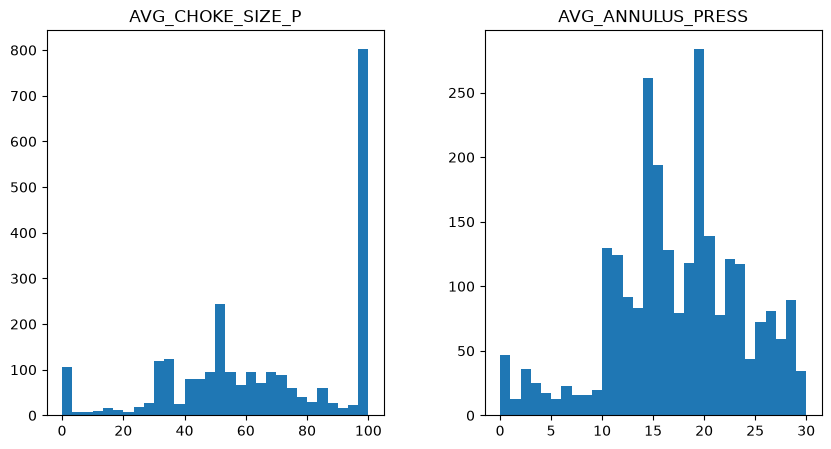

In [26]:
train_df.hist(bins=30,column=["AVG_CHOKE_SIZE_P","AVG_ANNULUS_PRESS"], grid=False, figsize=(10, 5))

<Axes: title={'center': 'BORE_OIL_VOL over time'}, xlabel='DATEPRD'>

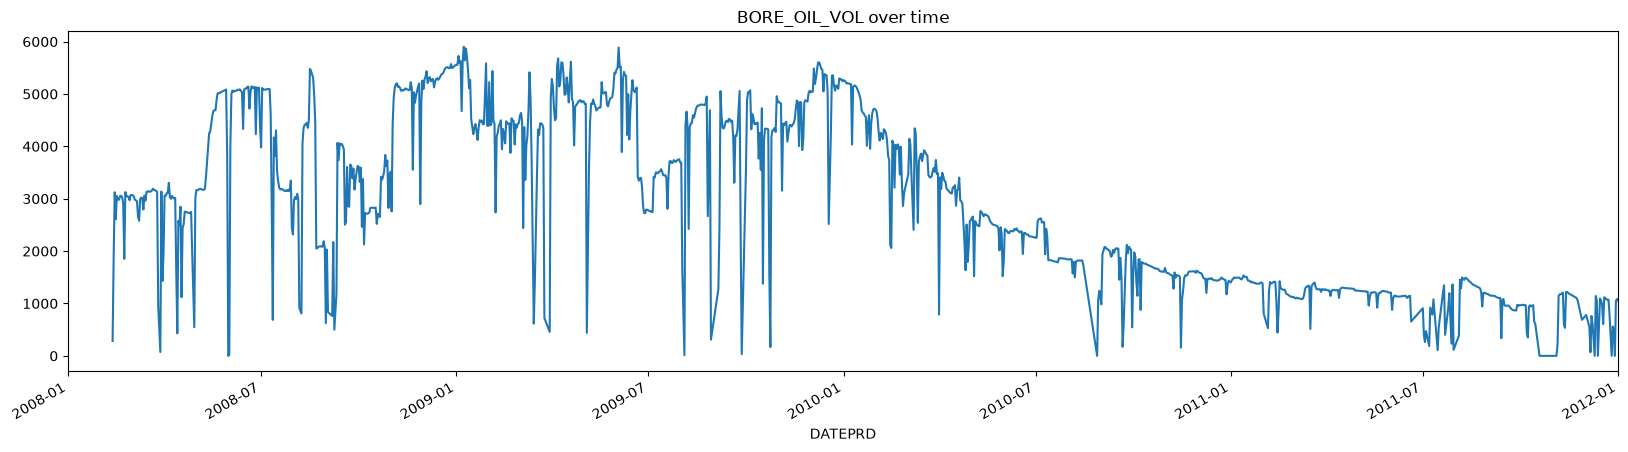

In [27]:
train_df["BORE_OIL_VOL"].plot(xlim=["2008-01-01", "2012"], figsize=(20,5), title="BORE_OIL_VOL over time")

In [28]:
pd.DataFrame(train_df["BORE_OIL_VOL"].resample(rule="YE").max())

,BORE_OIL_VOL
DATEPRD,
2008-12-31,5571.07
2009-12-31,5901.84
2010-12-31,5261.93
2011-12-31,1534.90
2012-12-31,1377.09
2013-12-31,618.44
2014-12-31,281.94
2015-12-31,1162.07


<Axes: title={'center': 'Yearly Max BORE_OIL_VOL over time'}, xlabel='DATEPRD'>

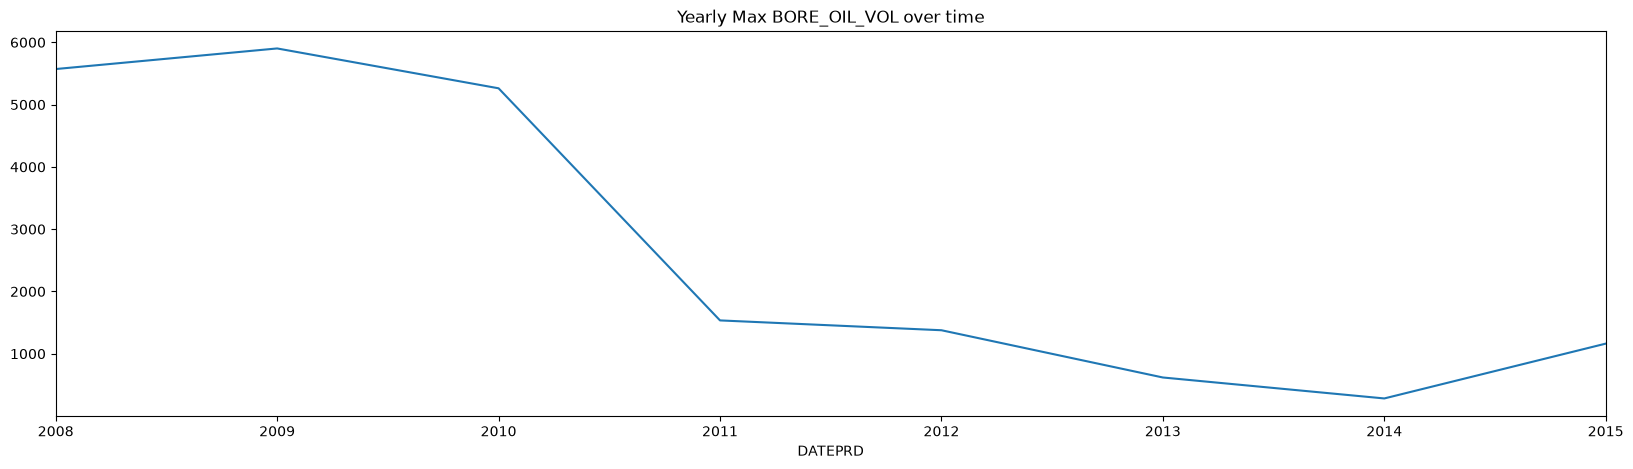

In [29]:
train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(figsize=(20,5), title="Yearly Max BORE_OIL_VOL over time")

<Axes: title={'center': 'Yearly Max BORE_OIL_VOL over time'}, xlabel='DATEPRD'>

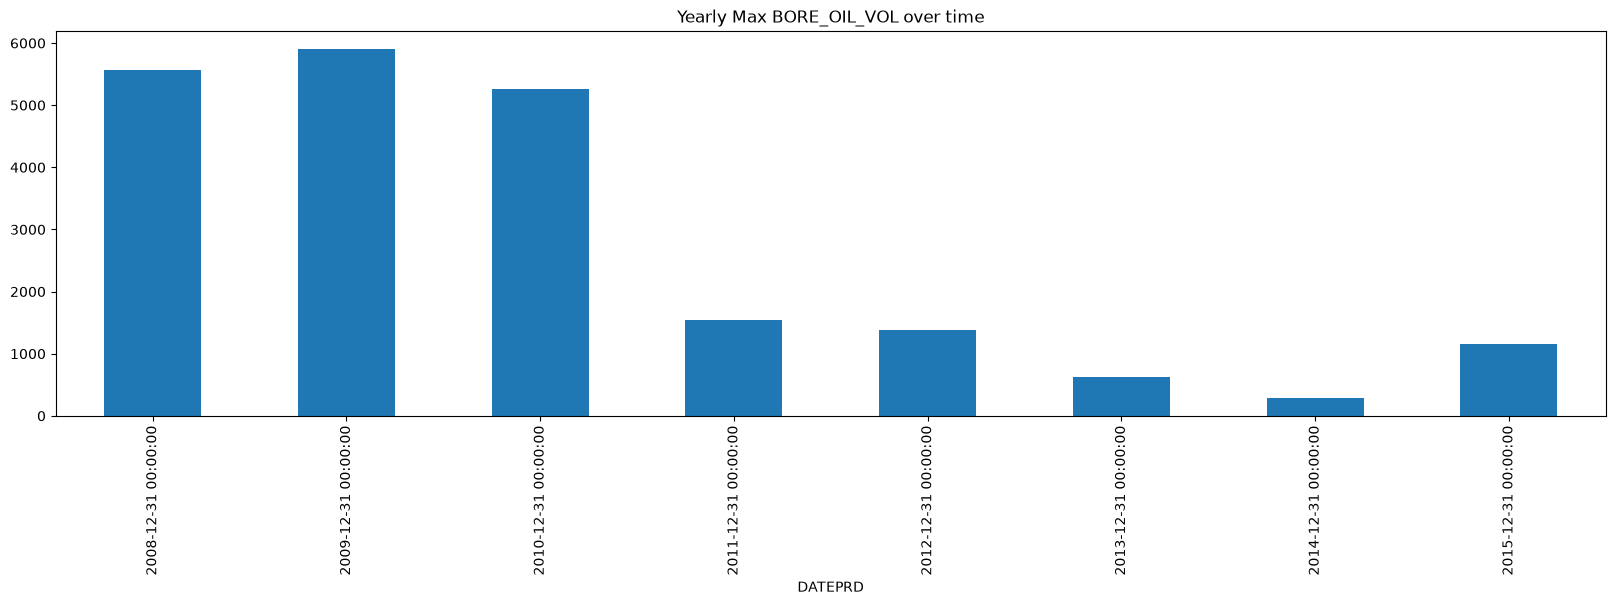

In [30]:
train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(x=train_df.index, kind="bar", figsize=(20,5), title="Yearly Max BORE_OIL_VOL over time")

In [31]:
train_df["rolling"]=train_df["BORE_OIL_VOL"].rolling(20).mean()

<Axes: title={'center': 'BORE_OIL_VOL with 30-day rolling mean'}, xlabel='DATEPRD'>

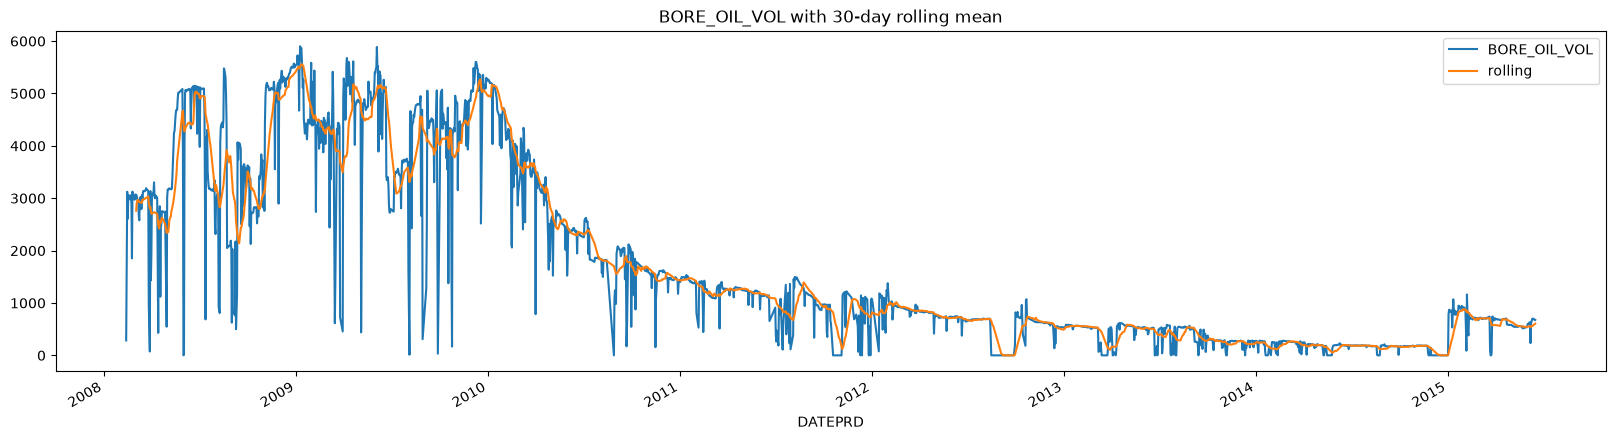

In [32]:
train_df[["BORE_OIL_VOL", "rolling"]].plot(figsize=(20,5), title="BORE_OIL_VOL with 30-day rolling mean")

In [33]:
pd.DataFrame(train_df["BORE_OIL_VOL"].resample("QE").mean())

,BORE_OIL_VOL
DATEPRD,
2008-03-31,2759.423333
2008-06-30,3819.976222
2008-09-30,3338.896782
2008-12-31,4420.787609
2009-03-31,4387.391429
2009-06-30,4715.826667
2009-09-30,3763.639146
2009-12-31,4575.617935
2010-03-31,4119.260930


In [34]:
train_df["rolling:50"]=train_df["BORE_OIL_VOL"].rolling(40).mean()

<Axes: title={'center': 'Quarterly Max BORE_OIL_VOL over time'}, xlabel='DATEPRD'>

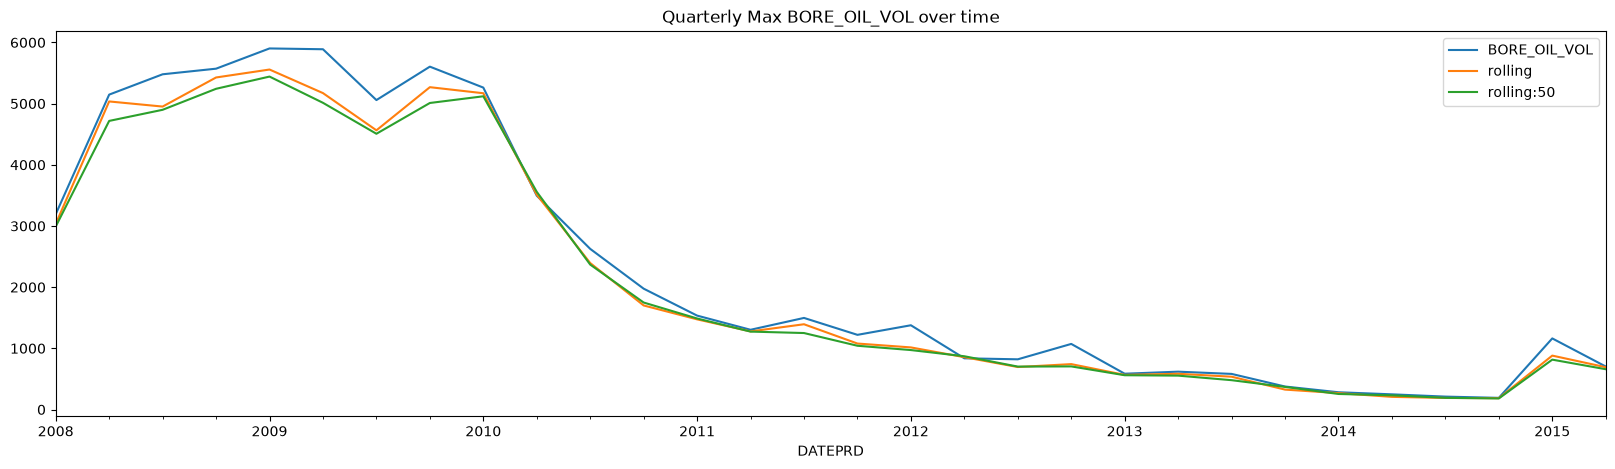

In [35]:
train_df[["BORE_OIL_VOL","rolling", "rolling:50"]].resample("QE").max().plot(figsize=(20,5), title="Quarterly Max BORE_OIL_VOL over time")

<Axes: title={'center': 'Expanding Mean of BORE_OIL_VOL over time'}, xlabel='Time', ylabel='Expanding Mean'>

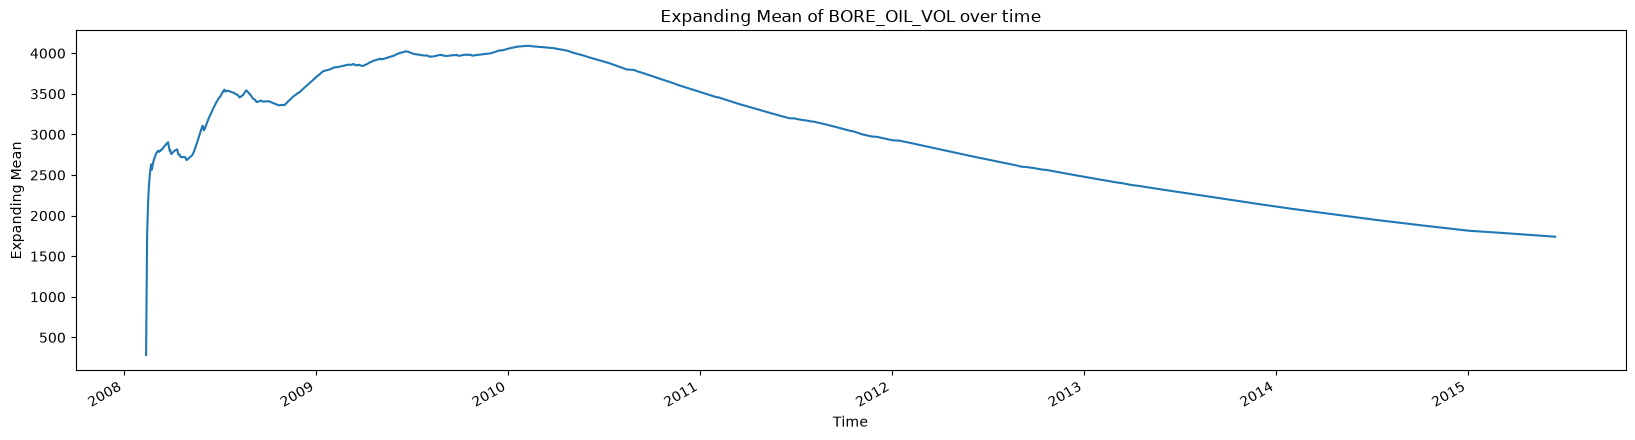

In [36]:
## best plot so far
train_df["BORE_OIL_VOL"].expanding().mean().plot(xlabel="Time", ylabel="Expanding Mean", figsize=(20,5), title="Expanding Mean of BORE_OIL_VOL over time")

### Statsmodels testing

In [37]:
train_df['Differenced_BORE_OIL_VOL'] = train_df['BORE_OIL_VOL'].diff()
 
# Drop missing values resulting from differencing
train_df.dropna(inplace=True)

In [38]:
print(train_df[['BORE_OIL_VOL', 'Differenced_BORE_OIL_VOL']].head())

            BORE_OIL_VOL  Differenced_BORE_OIL_VOL
DATEPRD                                           
2008-03-22       3172.12                    -20.02
2008-03-23       3160.26                    -11.86
2008-03-24       3153.35                     -6.91
2008-03-25       3130.58                    -22.77
2008-03-26        960.26                  -2170.32


<Axes: xlabel='DATEPRD'>

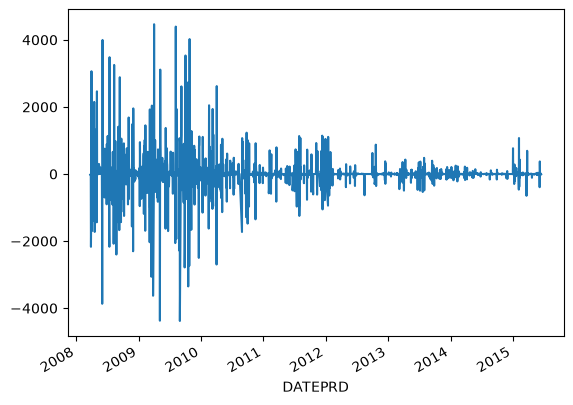

In [39]:
train_df['Differenced_BORE_OIL_VOL'].plot()

In [40]:
result = sm.tsa.stattools.adfuller(train_df['Differenced_BORE_OIL_VOL'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])

if result[1] < 0.05:
    print("Data is stationary")
else:
    print("Data is non-stationary")

ADF Statistic: -16.619135137506795
p-value: 1.7041662754631676e-29
Data is stationary


C:\Users\baqee\AppData\Local\Temp\ipykernel_23684\2861386677.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = sm.tsa.stattools.adfuller(train_df['Differenced_BORE_OIL_VOL'])


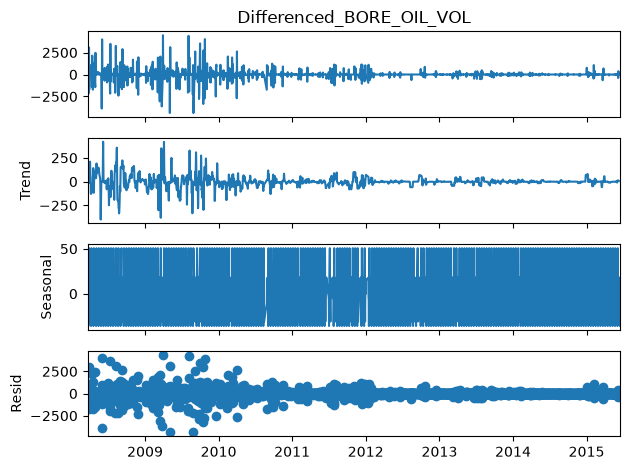

In [41]:
from statsmodels.tsa.seasonal import seasonal_decompose
result = seasonal_decompose(train_df["Differenced_BORE_OIL_VOL"], model='additive', period=12)
result.plot()
plt.show()



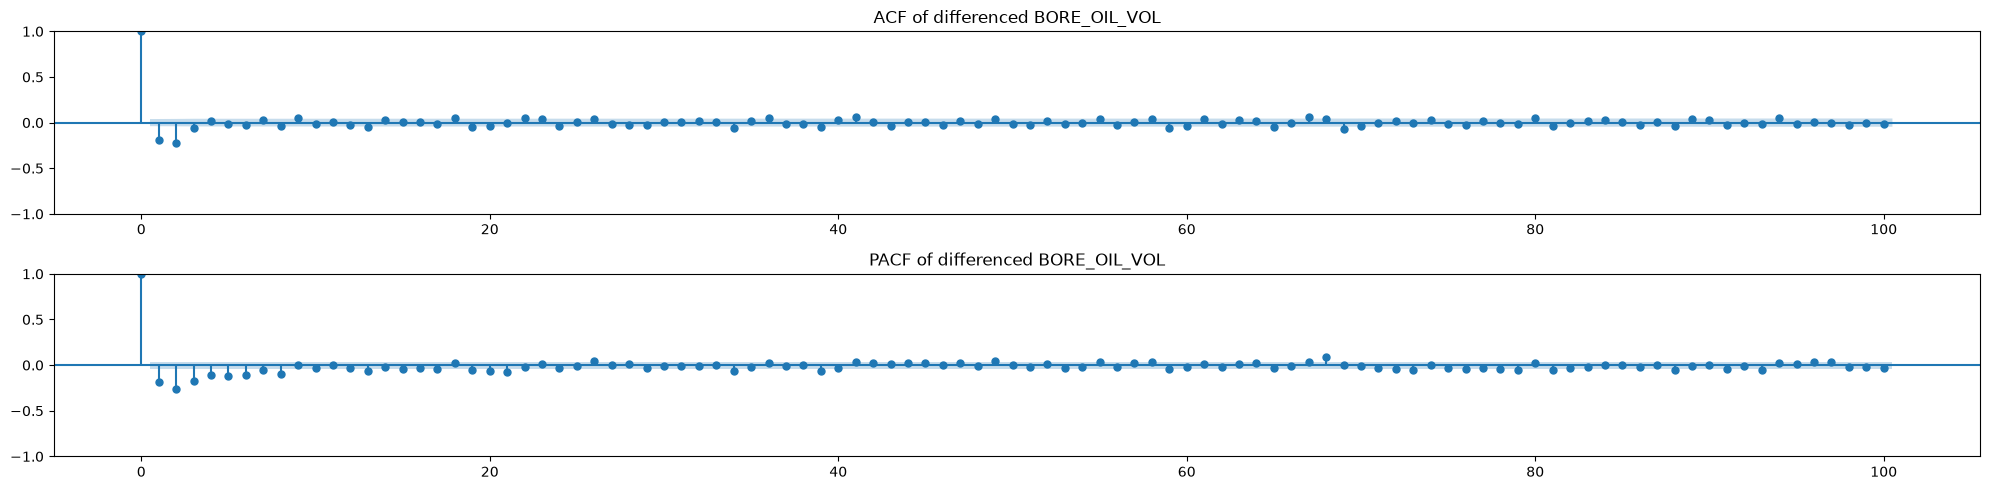

In [42]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

series = train_df["Differenced_BORE_OIL_VOL"].dropna()

fig, axes = plt.subplots(2, 1, figsize=(20, 5))
plot_acf(series, lags=100, ax=axes[0], title="ACF of differenced BORE_OIL_VOL")
plot_pacf(series, lags=100, ax=axes[1], method="ywadjusted", title="PACF of differenced BORE_OIL_VOL")
plt.tight_layout()
plt.show()


d --> from Differencing = 1
p--> from pacf = 3
q--> from acf = 2

## Build the model 

In [43]:
train_df["BORE_OIL_VOL"].index , test_df["BORE_OIL_VOL"].index

(DatetimeIndex(['2008-03-22', '2008-03-23', '2008-03-24', '2008-03-25',
                '2008-03-26', '2008-03-28', '2008-03-29', '2008-03-30',
                '2008-03-31', '2008-04-01',
                ...
                '2015-06-07', '2015-06-08', '2015-06-09', '2015-06-10',
                '2015-06-11', '2015-06-12', '2015-06-13', '2015-06-14',
                '2015-06-15', '2015-06-16'],
               dtype='datetime64[ns]', name='DATEPRD', length=2514, freq=None),
 DatetimeIndex(['2015-06-17', '2015-06-18', '2015-06-19', '2015-06-20',
                '2015-06-21', '2015-06-22', '2015-06-23', '2015-06-24',
                '2015-06-25', '2015-06-26',
                ...
                '2016-09-08', '2016-09-09', '2016-09-10', '2016-09-11',
                '2016-09-12', '2016-09-13', '2016-09-14', '2016-09-15',
                '2016-09-16', '2016-09-17'],
               dtype='datetime64[ns]', name='DATEPRD', length=459, freq=None))

### ARIMA

In [44]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train_df["BORE_OIL_VOL"], order=(3, 1, 2))
model_fit = arima_model.fit()

d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [45]:
model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           BORE_OIL_VOL   No. Observations:                 2514
Model:                 ARIMA(3, 1, 2)   Log Likelihood              -18805.271
Date:                Mon, 28 Sep 2026   AIC                          37622.542
Time:                        20:03:14   BIC                          37657.517
Sample:                             0   HQIC                         37635.236
                               - 2514                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1189      0.263     -0.452      0.651      -0.634       0.396
ar.L2          0.2051      0.132      1.554      0.120      -0.054       0.464
ar.L3         -0.0388      0.031     -1.232      0.218      -0.100       0.023
ma.L1         -0.2333      0.261     -0.893      0.372      -0.746       0.279
ma.L2         -0.5331      0.222     -2.400      0.016      -0.968      -0.098
sigma2       1.83e+05   1464.198    125.011      0.000     1.8e+05    1.86e+05
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):             76801.21
Prob(Q):                              0.95   Prob(JB):                         0.00
Heteroskedasticity (H):               0.02   Skew:                            -2.36
Prob(H) (two-sided):                  0.00   Kurtosis:                        29.67
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [79]:
train_y = train_df['BORE_OIL_VOL'].reset_index(drop=True)
model = ARIMA(train_y, order=(3, 1, 2))
model_fit1 = model.fit()

pred = model_fit1.forecast(steps=50)

d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [ ]:
test_df=test_df.merge(pred.rename("Predicted_BORE_OIL_VOL"), left_index=True, right_index=True, how="left")

In [83]:
pred = model_fit.forecast(steps=30)

pred.index = pd.date_range(
    start=train_df.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

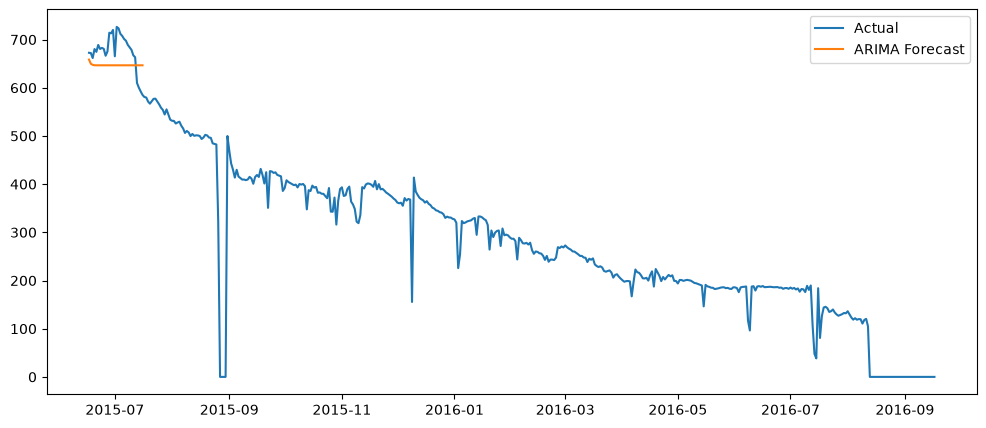

In [84]:
plt.figure(figsize=(12,5))

plt.plot(test_df.index, test_df["BORE_OIL_VOL"], label="Actual")
plt.plot(pred.index, pred, label="ARIMA Forecast")

plt.legend()
plt.show()

In [73]:

residuals = pd.Series(test_df["BORE_OIL_VOL"] - pred, index=test_df.index, name="Residuals")


<Axes: ylabel='Density'>

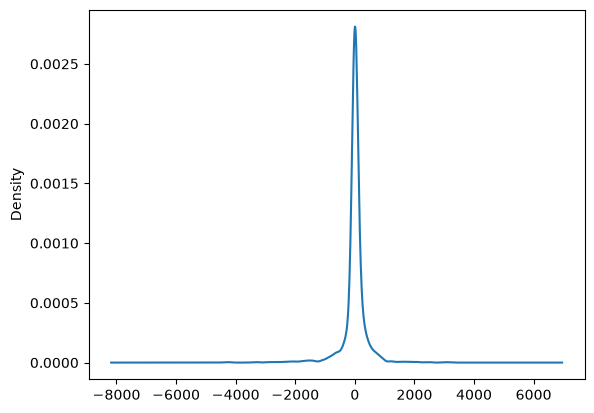

In [74]:
model_fit1.resid.plot(kind='kde')

### XGBoost

### LSTM